# End-to-end solutions

This page runs the whole pipeline on two settings.

| | initial condition | method | basis |
| --- | --- | --- | --- |
| Part 1 | a known point $\mathbf x_0$ | `Koopman` | `CarlemanBasis` |
| Part 2 | a density $\rho_0$ | `Liouville` | `GaussianHermiteBasis` |

Both parts end by comparing against a direct `scipy` integration of the same equation.

## Part 1: Koopman on a Carleman basis

$\mathbf x(0)=\mathbf x_0$ is known, so the answer is never an expectation value and the basis needs
no inner product. Carleman qualifies, even though a monomial is not square-integrable.

Take the basis functions as the observables, and one equation gives the whole solution:

$$\boldsymbol\phi(\mathbf x(t))=e^{At}\,\boldsymbol\phi(\mathbf x_0),
\qquad A=M^{\mathsf T},\quad M[\beta,\alpha]=\langle\beta\rvert\mathcal K\lvert\alpha\rangle.$$

$u_i$ is itself a basis function, so $u_i(t)$ is one row of $\boldsymbol\phi(\mathbf x(t))$.

The example is KPP–Fisher on a periodic ring of 6 sites. Carleman linearizes a nonlinear right-hand
side, so the reaction term stays:

$$\frac{du_i}{dt}=u_{i-1}-2u_i+u_{i+1}+u_i(1-u_i).$$

No `conditions` are passed below, so an index off the grid wraps, which is what makes the grid a
ring ([`02_ode`](02_ode.ipynb)).

In [1]:
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.linalg import expm

from lin_ode.basis import CarlemanBasis, TruncatedBasisSet
from lin_ode.operators import Koopman
from lin_ode import OperatorMatrix, OrdinaryDifferentialSystem

n_ring = 6
u, j = sp.IndexedBase("u"), sp.Idx("j", (0, n_ring - 1))
kpp_fisher = OrdinaryDifferentialSystem.from_sympy(
    u[j - 1] - 2 * u[j] + u[j + 1] + u[j] * (1 - u[j]), u, (j,)
)


def koopman_generator(basis: TruncatedBasisSet) -> np.ndarray:
    """A = M^T, so that d(phi)/dt = A phi."""
    states = [basis.structured_idx_of_flat_index(n) for n in range(len(basis))]
    matrix = OperatorMatrix(basis, Koopman().create_operator(kpp_fisher))[states, states]
    return np.array(matrix, dtype=float).T


def evolve_carleman(basis: TruncatedBasisSet, x_0: np.ndarray, times: np.ndarray) -> np.ndarray:
    """u_i(t) at every time in `times`, by exponentiating A onto phi(x_0) and slicing the
    degree-1 rows."""
    states = [basis.structured_idx_of_flat_index(n) for n in range(len(basis))]
    phi_0 = np.array([np.prod([x_0[int(s)] ** int(p) for s, p in state]) for state in states])
    rows = [basis.flat_index_of_basis_function(basis[(site, 1)]) for site in range(n_ring)]
    A = koopman_generator(basis)
    return np.array([(expm(A * t) @ phi_0)[rows] for t in times])


x_0 = np.where(np.isin(np.arange(n_ring), (2, 3)), 0.3, 0.05)
ring_times = np.linspace(0, 0.6, 7)

nonlinear = solve_ivp(
    lambda _, x: np.roll(x, 1) - 2 * x + np.roll(x, -1) + x * (1 - x),
    (0, ring_times[-1]), x_0, t_eval=ring_times, rtol=1e-12, atol=1e-14,
).y.T

for degree in (2, 3):
    basis = CarlemanBasis(n_ring, degree)
    error = np.abs(evolve_carleman(basis, x_0, ring_times) - nonlinear).max()
    print(f"degree {degree}: {len(basis):3} states, max |Carleman - exact| = {error:.2e}")

degree 2:  28 states, max |Carleman - exact| = 1.16e-02


degree 3:  84 states, max |Carleman - exact| = 2.24e-03


Degree 3 is five times more accurate than degree 2. Carleman is exact at $t=0$, and stays accurate
while the state stays near the expansion point.

The next cell starts further from the expansion point and runs four times longer.

In [2]:
far_times = np.linspace(0, 1.5, 4)
big_start = np.where(np.isin(np.arange(n_ring), (2, 3)), 0.9, 0.1)

diverging = evolve_carleman(CarlemanBasis(n_ring, 3), big_start, far_times)
reference = solve_ivp(
    lambda _, x: np.roll(x, 1) - 2 * x + np.roll(x, -1) + x * (1 - x),
    (0, far_times[-1]), big_start, t_eval=far_times, rtol=1e-12, atol=1e-14,
).y.T

for t, approx, exact in zip(far_times, diverging, reference):
    print(f"t={t:.1f}   u_2 Carleman = {approx[2]: .3f}   exact = {exact[2]: .3f}")

t=0.0   u_2 Carleman =  0.900   exact =  0.900
t=0.5   u_2 Carleman =  0.795   exact =  0.723
t=1.0   u_2 Carleman =  1.456   exact =  0.710
t=1.5   u_2 Carleman =  4.929   exact =  0.752



Truncation discards the coupling to degree $K+1$, and that coupling grows with $t$. The Carleman
solution therefore tracks the exact solution for a while and then departs.

## Part 2: Liouville on a Gauss–Hermite basis

The initial position is now a density $\rho_0$. The equation is centred advection–diffusion at unit
spacing, and an index off the grid contributes nothing:

$$\frac{du_k}{dt}=(u_{k+1}-u_{k-1})+\nu\,(u_{k-1}-2u_k+u_{k+1}).$$

Without the `conditions` in the next cell that index would wrap ([`02_ode`](02_ode.ipynb)), so the
two ends get their own stencils.

`Liouville` tracks the density $\rho$ rather than a trajectory $u(t)$, and an inner product with
$\rho$ gives the expectation value of an observable:

$$\boldsymbol\rho(t)=e^{Mt}\boldsymbol\rho(0),
\qquad
\langle g\rangle(t)=\sum_\alpha \rho_\alpha(t)\,\langle\psi_\alpha,g\rangle.$$

Both equations need an inner product, so the basis must be square-integrable. `OperatorMatrix`
raises `IncompatibleBasisError` on either Carleman basis here. Gauss–Hermite is square-integrable,
and is also orthonormal, which is what makes $\rho_\alpha$ the coefficient of $\psi_\alpha$.

### 1. The ODE

In [3]:
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from scipy.special import factorial

from lin_ode import DerivativeCondition, Facet
from lin_ode.basis import GaussianHermiteBasis
from lin_ode.operators import Liouville
from lin_ode.vector import Vector

# numpy, sympy, solve_ivp, expm, TruncatedBasisSet and OrdinaryDifferentialSystem
# were imported in Part 1

n_sites = 5
u, k = sp.IndexedBase("u"), sp.Idx("k", (0, n_sites - 1))


def advection_diffusion(nu: float) -> sp.Expr:
    """The right-hand side above, as a sympy expression."""
    return (u[k + 1] - u[k - 1]) + nu * (u[k - 1] - 2 * u[k] + u[k + 1])


def ode_system(nu: float) -> OrdinaryDifferentialSystem:
    """The right-hand side, with a zero neighbour outside each end of the grid."""
    return OrdinaryDifferentialSystem.from_sympy(
        advection_diffusion(nu),
        u,
        (k,),
        conditions=[
            DerivativeCondition(Facet.low(k), u[k + 1] + nu * (-2 * u[k] + u[k + 1])),
            DerivativeCondition(Facet.high(k), -u[k - 1] + nu * (u[k - 1] - 2 * u[k])),
        ],
    )


StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors


### 2. The linearized operator, $M_{\beta\alpha}=\langle\psi_\beta,\mathcal L\,\psi_\alpha\rangle$

In [4]:
def basis_states(basis: TruncatedBasisSet) -> list[StateLabel]:
    """Every state of the basis, as the (site, power) labels everything else is sliced by."""
    return [basis.structured_idx_of_flat_index(n) for n in range(len(basis))]


def liouville_matrix(ode: OrdinaryDifferentialSystem, basis: TruncatedBasisSet) -> np.ndarray:
    """M[beta, alpha] = <psi_beta, L psi_alpha>, as a dense array."""
    states = basis_states(basis)
    return np.array(
        OperatorMatrix(basis, Liouville().create_operator(ode))[states, states], dtype=float
    )


basis = GaussianHermiteBasis(n_sites, degree=3)
M = liouville_matrix(ode_system(nu=0.0), basis)

print(f"{len(basis)} states, {np.count_nonzero(M)} nonzero entries")

56 states, 168 nonzero entries


### 3. The initial density, a displaced Gaussian

A Gaussian is not a polynomial, so `GHPolyProjector` cannot project it
([`06_vector`](06_vector.ipynb)). The coherent-state coefficients are known in closed form for unit
width displaced to $d$:

$$\langle\psi_n,\rho_0\rangle=e^{-d^{2}/4}\,\frac{(d/\sqrt2)^{n}}{\sqrt{n!}}.$$

The coefficients decay factorially, so a low degree already captures the density.

In [5]:
def coherent_coefficients(displacement: float, degree: int) -> np.ndarray:
    """<psi_n, psi_0(. - d)> = exp(-d^2/4) (d/sqrt2)^n / sqrt(n!), for n = 0..degree."""
    n = np.arange(degree + 1)
    return np.exp(-(displacement**2) / 4) * (displacement / np.sqrt(2)) ** n / np.sqrt(factorial(n))


def displaced_gaussian(basis: TruncatedBasisSet, displacement: np.ndarray) -> np.ndarray:
    """rho(0) for prod_k psi_0(u_k - d_k): the per-site coefficients, multiplied."""
    per_site = [coherent_coefficients(d, basis.degree) for d in displacement]
    rho = np.ones(len(basis))
    for flat, state in enumerate(basis_states(basis)):
        order = dict((int(site), int(power)) for site, power in state)
        for site, coefficients in enumerate(per_site):
            rho[flat] *= coefficients[order.get(site, 0)]
    return rho


displacement = 0.7 * np.sin(np.pi * (np.arange(n_sites) + 1) / (n_sites + 1))
rho_0 = displaced_gaussian(basis, displacement)

centre = coherent_coefficients(displacement[n_sites // 2], degree=5)
print("displacement d_k       :", np.round(displacement, 4))
print("centre site, c_n / c_0 :", np.round(centre / centre[0], 4), " <- an infinite tail")
print(f"rho(0) is dense: {np.count_nonzero(rho_0)} of {len(basis)} entries nonzero")

displacement d_k       : [0.35   0.6062 0.7    0.6062 0.35  ]
centre site, c_n / c_0 : [1.     0.495  0.1732 0.0495 0.0123 0.0027]  <- an infinite tail
rho(0) is dense: 56 of 56 entries nonzero


### 4. The observable

$(\boldsymbol w_g)_\alpha=\langle\psi_\alpha,g\rangle$, one `Vector` call per site. Both
observables here are polynomials, so `GHPolyProjector` handles them and no extra projector is
needed. The labels printed below are the ones where the coefficient is nonzero.

In [6]:
def observable_vector(g: sp.Expr, basis: TruncatedBasisSet) -> np.ndarray:
    """w[alpha] = <psi_alpha, g>, via the basis's own projectors."""
    projected = Vector(g, basis, u)
    return np.array([float(projected[state]) for state in basis_states(basis)])


w_one = observable_vector(sp.Integer(1), basis)  # the normalisation, g = 1
w_field = [observable_vector(u[site], basis) for site in range(n_sites)]

print("<psi_a, 1>   nonzero at:", [s for s, v in zip(basis_states(basis), w_one) if v])
print("<psi_a, u_0> nonzero at:", [s for s, v in zip(basis_states(basis), w_field[0]) if v])

<psi_a, 1>   nonzero at: [(), ((0, 2),), ((1, 2),), ((2, 2),), ((3, 2),), ((4, 2),)]
<psi_a, u_0> nonzero at: [((0, 1),), ((0, 3),), ((0, 1), (1, 2)), ((0, 1), (2, 2)), ((0, 1), (3, 2)), ((0, 1), (4, 2))]


### 5. Transport, then take the inner product

$$\boldsymbol\rho(t)=e^{Mt}\boldsymbol\rho(0),
\qquad
\langle g\rangle(t)=\frac{\boldsymbol w_g^{\mathsf T}\,\boldsymbol\rho(t)}
{\boldsymbol w_1^{\mathsf T}\,\boldsymbol\rho(t)}.$$

The matrix moves the density and never touches the observable. The division normalises, because a
truncated $\boldsymbol\rho$ does not integrate to exactly 1.

In Part 1 $e^{At}$ moved the basis functions, and the observable was a row index. Here the same
exponential moves the density instead.

In [7]:
def transport(M: np.ndarray, rho_0: np.ndarray, t: float) -> np.ndarray:
    """rho(t) = exp(M t) rho(0)."""
    return expm(M * t) @ rho_0


def expectation(w_g: np.ndarray, rho: np.ndarray, w_one: np.ndarray) -> float:
    """<g> = <w_g, rho> / <w_1, rho>, an inner product of two coefficient vectors."""
    return float(np.dot(w_g, rho) / np.dot(w_one, rho))


rho_at_one = transport(M, rho_0, t=1.0)

print("<w_g, rho(1)>   =", np.dot(w_field[0], rho_at_one))
print("<w_1, rho(1)>   =", np.dot(w_one, rho_at_one))
print("<u_0>(1)        =", expectation(w_field[0], rho_at_one, w_one))

<w_g, rho(1)>   = 22.30403055146435
<w_1, rho(1)>   = 22.404561220015673
<u_0>(1)        = 0.9955129374075172


In [8]:
def get_observable_evolution(
    M: np.ndarray,
    rho_0: np.ndarray,
    observables: list[np.ndarray],
    w_one: np.ndarray,
    times: np.ndarray,
) -> np.ndarray:
    """<g>(t) for each observable in `observables`, at every time."""
    return np.array([
        [expectation(w_g, transport(M, rho_0, t), w_one) for w_g in observables] for t in times
    ])


times = np.linspace(0, 2, 21)
answer = get_observable_evolution(M, rho_0, w_field, w_one, times)

# degree 3 is odd, so the truncated mean recovers the displacement exactly
assert np.allclose(answer[0], displacement)

print("<u_k> at t=0 ", np.round(answer[0], 4), " = d_k")
print("<u_k> at t=2 ", np.round(answer[-1], 4))

<u_k> at t=0  [0.35   0.6062 0.7    0.6062 0.35  ]  = d_k
<u_k> at t=2  [ 1.1286 -0.3163  0.2454 -0.1882  0.0261]


### 6. Compare against scipy

The flow is linear, so the mean of the density follows the same ODE as a single trajectory.
Integrating that trajectory directly gives a reference.

In [9]:
def numerical_solution(nu: float, start: np.ndarray, times: np.ndarray) -> np.ndarray:
    """solve_ivp on the same right-hand side, with the same Dirichlet ends."""

    def rhs(t: float, values: np.ndarray) -> np.ndarray:
        padded = np.concatenate(([0.0], values, [0.0]))
        laplacian = padded[2:] - 2 * values + padded[:-2]
        return (padded[2:] - padded[:-2]) + nu * laplacian

    return solve_ivp(rhs, [0, times[-1]], start, t_eval=times, rtol=1e-11, atol=1e-13).y.T


reference = numerical_solution(0.0, displacement, times)

print(f"max |Liouville+GH - scipy| = {np.abs(answer - reference).max():.2e}")

max |Liouville+GH - scipy| = 2.94e-12


### 7. Truncation degree and viscosity

The steps above hold the degree and the viscosity fixed. Both change the answer, in different ways.

In [10]:
def pipeline_run(nu: float, degree: int) -> tuple[np.ndarray, np.ndarray]:
    """The whole pipeline at one viscosity and degree -> (<u_k>(t), scipy reference)."""
    basis = GaussianHermiteBasis(n_sites, degree)
    M = liouville_matrix(ode_system(nu), basis)
    rho_0 = displaced_gaussian(basis, displacement)
    w_one = observable_vector(sp.Integer(1), basis)
    w_field = [observable_vector(u[site], basis) for site in range(n_sites)]

    answer = get_observable_evolution(M, rho_0, w_field, w_one, times)
    return answer, numerical_solution(nu, displacement, times)


runs = {(nu, degree): pipeline_run(nu, degree)
        for nu, degree in [(0.0, 1), (0.0, 2), (0.0, 3), (0.15, 2), (0.15, 3)]}

for (nu, degree), (got, truth) in runs.items():
    error = np.abs(got - truth).max(1)
    parity = "odd " if degree % 2 else "even"
    print(f"nu = {nu:<5} degree {degree} ({parity})   max |GH - scipy| @ t = 0, 1, 2:"
          f"  {error[0]:.1e}  {error[10]:.1e}  {error[-1]:.1e}")

nu = 0.0   degree 1 (odd )   max |GH - scipy| @ t = 0, 1, 2:  2.2e-16  2.1e-12  2.9e-12
nu = 0.0   degree 2 (even)   max |GH - scipy| @ t = 0, 1, 2:  1.9e-01  2.7e-01  3.0e-01
nu = 0.0   degree 3 (odd )   max |GH - scipy| @ t = 0, 1, 2:  1.1e-16  2.1e-12  2.9e-12
nu = 0.15  degree 2 (even)   max |GH - scipy| @ t = 0, 1, 2:  1.9e-01  1.0e+00  4.5e+00
nu = 0.15  degree 3 (odd )   max |GH - scipy| @ t = 0, 1, 2:  1.1e-16  1.1e-01  1.2e+00


### 8. Expectation values across the grid

$\langle u_k\rangle$ across the grid, one curve per time.

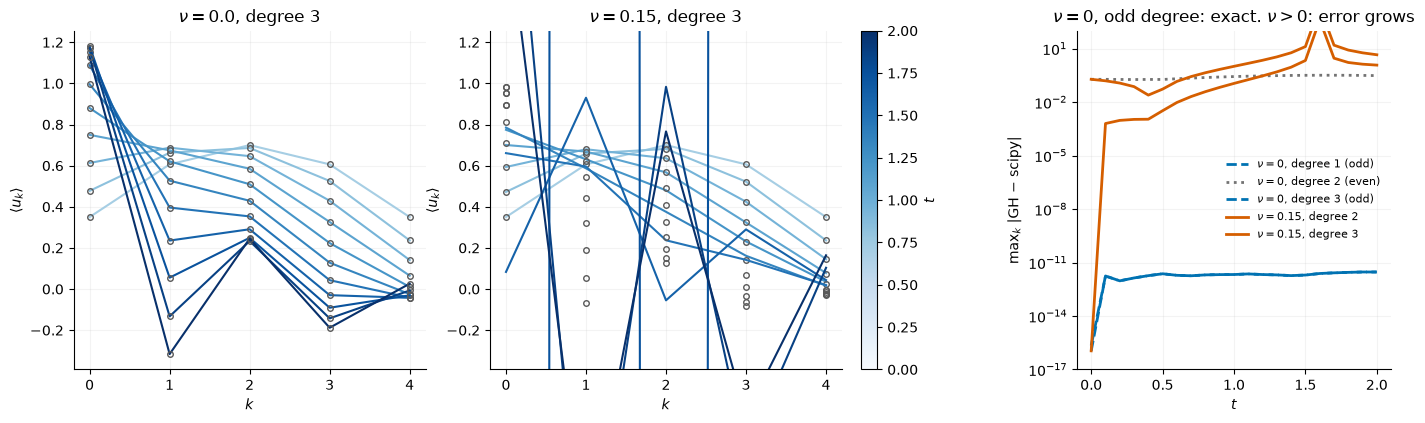

In [11]:
sites = np.arange(n_sites)
shown = range(0, len(times), 2)
colours = plt.get_cmap("Blues")(np.linspace(0.35, 1.0, len(times)))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), width_ratios=[1.35, 1.35, 1])

for ax, nu in zip(axes, (0.0, 0.15)):
    got, truth = runs[(nu, 3)]
    for step in shown:
        ax.plot(sites, got[step], "-", color=colours[step], lw=1.5)
        ax.plot(sites, truth[step], "o", color="0.35", ms=4, mfc="none", lw=0)
    ax.set(xlabel="$k$", ylabel=r"$\langle u_k \rangle$", xticks=sites,
           title=rf"$\nu={nu}$, degree 3")
axes[1].set_ylim(axes[0].get_ylim())  # same frame: the viscous curves leave it


def error_style(nu: float, degree: int) -> tuple[str, str, str]:
    """Colour by what actually distinguishes a curve: viscosity, then degree parity."""
    if nu:
        return "#D55E00", "-", rf"$\nu={nu}$, degree {degree}"
    if degree % 2:
        return "#0072B2", "--", rf"$\nu=0$, degree {degree} (odd)"
    return "0.45", ":", rf"$\nu=0$, degree {degree} (even)"


for (nu, degree), (got, truth) in runs.items():
    colour, dash, label = error_style(nu, degree)
    axes[2].semilogy(times, np.maximum(np.abs(got - truth).max(1), 1e-17),
                     dash, color=colour, lw=2, label=label)
axes[2].set(xlabel="$t$", ylabel=r"max$_k$ $|$GH $-$ scipy$|$", ylim=(1e-17, 1e2),
            title=r"$\nu=0$, odd degree: exact. $\nu>0$: error grows")
axes[2].legend(frameon=False, fontsize=8, loc="center right")

for ax in axes:
    ax.grid(alpha=0.15)
    ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(ScalarMappable(cmap="Blues", norm=plt.Normalize(0, times[-1])),
             ax=axes[:2], label="$t$", pad=0.02)
plt.show()

The left panel is $\nu=0$. The mean advects with no diffusion, and the `lin_ode` curves match the
reference.

The right panel adds viscosity. Viscosity damps the profile and shortens the time over which the two
agree.

**Degree parity.** $\langle\psi_n,u\rangle$ is nonzero only for odd $n$, and
$\langle\psi_n,u^2\rangle$ only for even $n$. A degree-1 observable therefore reads the odd block,
and a degree-2 observable reads the even block. Raising the truncation degree by one adds nothing to
an observable of the opposite parity.

**Viscosity.** The divergence is $\nabla\!\cdot\!f=-2N\nu$, which vanishes only at $\nu=0$. That is
the one case where $\mathcal L$ and $\mathcal L_{\rm KvN}$ reduce to $\mathcal K$ up to a sign.

---

[← Boundary conditions](07_boundary_conditions.ipynb) · [Notebook index](../README.md) · [Serialization →](09_serialization.ipynb)